# Compare change-point detection methods

Compares methods (binseg, Pelt, BottomUp, Window, KernelCPD, ...) across cost functions using each method's merged `conclusion.csv` and `summary.csv`. Metrics below are **test-set** (held-out) results (`test_f1`, `test_precision`, `test_recall`) unless noted otherwise -- `summary.csv` / the grid-search landscape plot are **train-set** diagnostics used to pick `best_pen` / `best_min_size`.

Dynp (dynamic programming) is not included yet -- its grid search is still running. Add it to `METHODS` below once `Dynp/results/dynp_grid_red_snr3_{conclusion,summary,raw}.csv` exist, and rerun the notebook.

**To add a new method later**: add one entry to `METHODS` in the cell below (name -> its results dir + filename prefix) and rerun the notebook. Everything else adapts automatically.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from adjustText import adjust_text

pd.set_option("display.width", 120)
BASE = os.getcwd()

In [2]:
# --- add new methods here: name -> (results dir, filename prefix) ---
# expects <dir>/<prefix>_conclusion.csv, <prefix>_summary.csv, <prefix>_raw.csv
METHODS = {
    "binseg":    (os.path.join(BASE, "binseg/results"),         "binseg_grid_red_snr3"),
    "Pelt":      (os.path.join(BASE, "Pelt/results_pelt"),      "pelt_grid_red_snr3"),
    "BottomUp":  (os.path.join(BASE, "BottomUp/results"),       "bottomup_grid_red_snr3"),
    "Window":    (os.path.join(BASE, "Window/results"),         "window_grid_red_snr3"),
    "KernelCPD": (os.path.join(BASE, "KernelCPD/results"),      "kernelcpd_grid_red_snr3"),
    "Dynp":    (os.path.join(BASE, "Dynp/results"),           "dynp_grid_red_snr3"), 
}

def path_for(method, kind):
    """kind is 'conclusion', 'summary', or 'raw'."""
    dir_, prefix = METHODS[method]
    return os.path.join(dir_, f"{prefix}_{kind}.csv")

# validated categorical palette (dataviz skill), fixed order -- assigned by
# position, never cycled. Past 8 methods, fold extras into "Other" or facet.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

if len(METHODS) > len(PALETTE):
    print(f"warning: {len(METHODS)} methods but only {len(PALETTE)} validated colors -- "
          "extras will repeat a color; consider faceting instead.")

METHOD_COLORS = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(METHODS)}

# validated sequential blue ramp (dataviz skill), light -> dark, for magnitude encodings (heatmaps)
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list("seq_blue", [
    "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b",
])

In [3]:
def load_all(kind):
    """kind is 'conclusion', 'summary', or 'raw'. Returns one concatenated df tagged with 'method'."""
    frames = []
    for method in METHODS:
        path = path_for(method, kind)
        if not os.path.exists(path):
            print(f"[skip] {method}: no {kind}.csv found at {path}")
            continue
        df = pd.read_csv(path)
        df["method"] = method
        frames.append(df)
    if not frames:
        raise SystemExit(f"No {kind}.csv files found for any method.")
    return pd.concat(frames, ignore_index=True)

all_df = load_all("conclusion")
summary_df = load_all("summary")
all_df.head()

,cost,best_pen,best_min_size,best_jump,train_f1,train_precision,train_recall,test_f1,test_precision,test_recall,...,seed_budget,n_train_seeds,n_test_seeds,train_seeds,test_seeds,method,best_width,width_range,best_n_bkps,n_bkps_range
0,l2,2.169,30,1,0.798206,0.828769,0.773969,0.789272,0.826906,0.755610,...,light,14,6,"0,1,2,3,5,8,9,11,13,15,16,17,18,19","4,6,7,10,12,14",binseg,NaN,NaN,NaN,NaN
1,mahalanobis,16.816,30,1,0.796129,0.814670,0.782965,0.788635,0.823220,0.757630,...,light,14,6,"0,1,2,3,5,8,9,11,13,15,16,17,18,19","4,6,7,10,12,14",binseg,NaN,NaN,NaN,NaN
2,rbf,13.895,5,1,0.750230,0.795142,0.714433,0.744918,0.810867,0.690990,...,HEAVY,7,3,"0,1,3,11,16,17,18","5,8,15",binseg,NaN,NaN,NaN,NaN
3,normal,76.324,30,1,0.772870,0.789760,0.765412,0.730142,0.750917,0.716187,...,light,14,6,"0,1,2,3,5,8,9,11,13,15,16,17,18,19","4,6,7,10,12,14",binseg,NaN,NaN,NaN,NaN
4,rank,13.895,30,1,0.708324,0.675401,0.750803,0.722131,0.717320,0.734325,...,light,14,6,"0,1,2,3,5,8,9,11,13,15,16,17,18,19","4,6,7,10,12,14",binseg,NaN,NaN,NaN,NaN


## test f1 by cost function x method

In [4]:
pivot_f1 = all_df.pivot_table(index="cost", columns="method", values="test_f1")
pivot_f1["mean"] = pivot_f1.mean(axis=1, skipna=True)
pivot_f1 = pivot_f1.sort_values("mean", ascending=False)
pivot_f1.round(3)

method,BottomUp,Dynp,KernelCPD,Pelt,Window,binseg,mean
cost,,,,,,,
l2,0.854,0.854,NaN,0.857,0.697,0.789,0.810
rbf,0.798,0.774,0.808,0.818,0.651,0.745,0.766
normal,0.778,0.814,NaN,0.784,0.615,0.730,0.744
l1,0.815,0.837,NaN,0.826,0.534,0.693,0.741
mahalanobis,0.825,0.859,NaN,0.855,0.361,0.789,0.738
rank,0.757,0.779,NaN,0.749,0.672,0.722,0.736
clinear,0.533,0.526,NaN,0.508,0.012,0.434,0.403
linear,0.000,0.347,0.857,0.000,0.000,0.000,0.201
ar,0.000,0.667,NaN,0.000,NaN,0.000,0.167


## Best cost function per method (test set)

In [5]:
for method in METHODS:
    sub = all_df[all_df["method"] == method]
    if sub.empty:
        continue
    best = sub.loc[sub["test_f1"].idxmax()]
    print(f"{method:10s}: {best['cost']:12s} test_f1={best['test_f1']:.3f} "
          f"(precision={best['test_precision']:.3f}, recall={best['test_recall']:.3f})")

binseg    : l2           test_f1=0.789 (precision=0.827, recall=0.756)
Pelt      : l2           test_f1=0.857 (precision=0.877, recall=0.838)
BottomUp  : l2           test_f1=0.854 (precision=0.855, recall=0.854)
Window    : l2           test_f1=0.697 (precision=0.647, recall=0.764)
KernelCPD : linear       test_f1=0.857 (precision=0.877, recall=0.838)
Dynp      : mahalanobis  test_f1=0.859 (precision=0.844, recall=0.876)


## Needs attention

- **f1 == 0** -- the cost function failed outright, check its implementation/params.
- **on_edge == True** -- the best pen/min_size sits at the edge of the searched grid, so the true optimum may lie outside it. Widen `pen_range` / `min_size_range` and rerun.

In [6]:
failed = all_df[all_df["test_f1"] == 0]
print("Failed outright (test_f1 == 0):")
display(failed[["method", "cost"]].reset_index(drop=True))

Failed outright (test_f1 == 0):


,method,cost
0,binseg,ar
1,binseg,linear
2,Pelt,linear
3,Pelt,ar
4,BottomUp,ar
5,BottomUp,linear
6,Window,linear


In [7]:
on_edge = all_df[(all_df["on_edge"] == True) & (all_df["test_f1"] > 0)]  # noqa: E712
print("Best params on the edge of the search grid:")
display(on_edge[["method", "cost", "best_pen", "pen_range", "best_min_size", "min_size_range"]].reset_index(drop=True))

Best params on the edge of the search grid:


,method,cost,best_pen,pen_range,best_min_size,min_size_range
0,binseg,rbf,13.8950,1-100,5,5-50
1,Pelt,mahalanobis,19.2750,0.05-52,5,5-50
2,Pelt,rbf,16.8160,1-52,5,5-50
3,Pelt,normal,123.5510,1-200,5,5-50
4,Pelt,rank,26.8270,1-100,5,5-50
5,Pelt,clinear,1.6190,0.005-200,5,5-50
6,Pelt,l2,2.1690,0.05-200,5,5-50
7,BottomUp,normal,123.5510,1-200,5,5-50
8,Window,l2,0.0001,0.0001-0.05,5,5-50
9,Window,rank,0.0500,0.05-100,5,5-50


## Visualizations

### test f1 heatmap (cost x method)

Same numbers as the table above, but a heatmap scales far better than grouped bars once more methods are added -- it stays readable instead of the bar clusters getting crowded.

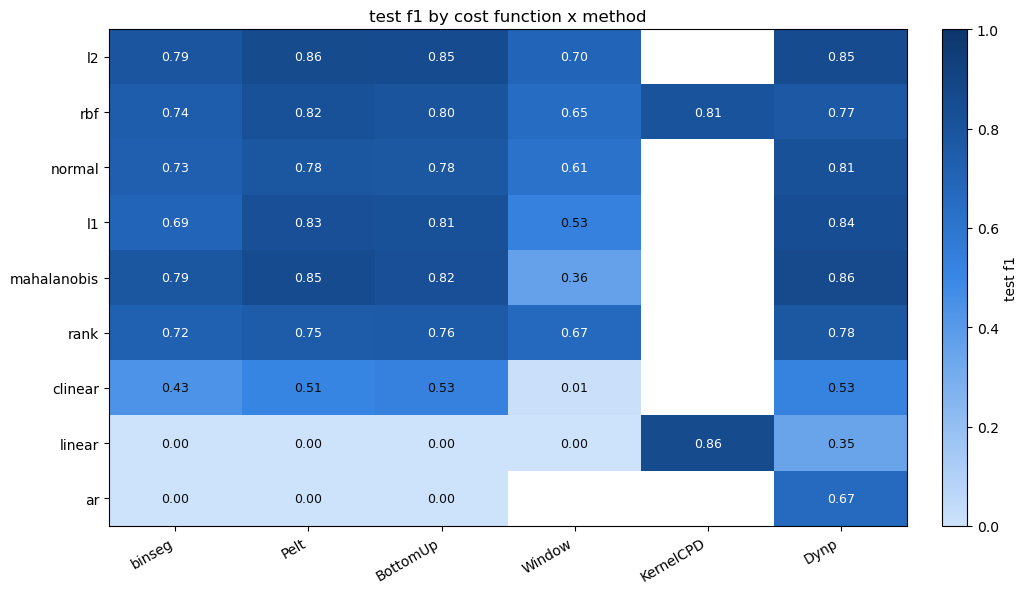

In [8]:
def plot_f1_heatmap(all_df, methods):
    pivot = all_df.pivot_table(index="cost", columns="method", values="test_f1")
    pivot = pivot[[m for m in methods if m in pivot.columns]]
    pivot = pivot.loc[pivot.mean(axis=1, skipna=True).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(1.4 * len(pivot.columns) + 2, 0.45 * len(pivot) + 2))
    im = ax.imshow(pivot.values, cmap=SEQUENTIAL_BLUE, vmin=0, vmax=1, aspect="auto")

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            if np.isnan(val):
                continue
            text_color = "#ffffff" if val > 0.55 else "#0b0b0b"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=9)

    ax.set_title("test f1 by cost function x method")
    fig.colorbar(im, ax=ax, label="test f1", fraction=0.046, pad=0.04)
    fig.tight_layout()
    return fig

fig = plot_f1_heatmap(all_df, METHODS)
plt.show()

### Precision vs. recall (test set)

f1 alone hides *why* a cost function underperforms. This separates over-segmenting (low precision, high recall) from under-segmenting (high precision, low recall). Dashed gray curves are f1 iso-lines.

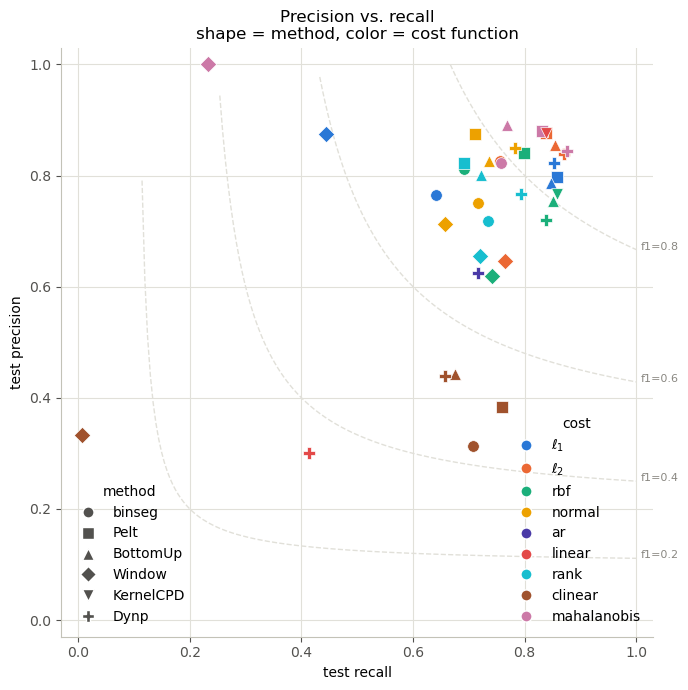

In [9]:
# fixed order for cost functions (matches the order introduced in Dynp's notebook)
REAL_COSTS = ['l1', 'l2', 'rbf', 'normal', 'ar', 'linear', 'rank', 'clinear', 'mahalanobis']
NEUTRAL = "#898781"  # methods with no cost sub-choice (KS test, LERM) -- fixed, not cycled

# dedicated 9-color categorical palette for cost functions -- separate from PALETTE
# (which stays 8 slots for METHODS) because 9 cost functions need a 9th distinct hue.
# Chosen for normal-vision distinctness (validated: lightness band + chroma floor pass;
# all-pairs CVD separation has known FAILs past ~3 series at this saturation -- an
# inherent limit of an 8-hue system pushed to 9 slots in a scatter plot, not something
# fixable by re-picking hex values -- so treat this as "distinct for normal vision",
# not colorblind-guaranteed).
COST_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7",
                "#e34948", "#17becf", "#a0522d", "#cc79a7"]

if len(REAL_COSTS) > len(COST_PALETTE):
    print(f"warning: {len(REAL_COSTS)} cost functions but only {len(COST_PALETTE)} colors -- "
          f"'{REAL_COSTS[len(COST_PALETTE)]}' repeats '{REAL_COSTS[0]}'\\'s color. Color carries real "
          "information here (unlike method's shape+color redundancy), so consider folding two "
          "similar-behaving cost functions (e.g. ar/linear, both near-zero f1 everywhere) into one "
          "bucket instead of letting them collide.")

COST_COLORS = {c: COST_PALETTE[i % len(COST_PALETTE)] for i, c in enumerate(REAL_COSTS)}

COST_ORDER = REAL_COSTS 

# display labels for the legend -- l1/l2 render as the math symbol ell (matplotlib
# mathtext, no LaTeX install needed) instead of the letter "l" next to a digit.
COST_LABELS = {"l1": r"$\ell_1$", "l2": r"$\ell_2$"}

def cost_label(c):
    return COST_LABELS.get(c, c)

MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

if len(METHODS) > len(MARKERS):
    print(f"warning: {len(METHODS)} methods but only {len(MARKERS)} distinct marker shapes -- "
          "extras will repeat a shape; consider faceting instead.")

METHOD_MARKERS = {m: MARKERS[i % len(MARKERS)] for i, m in enumerate(METHODS)}

from matplotlib.lines import Line2D

def plot_precision_recall(all_df, methods, costs, markers, colors):
    fig, ax = plt.subplots(figsize=(7, 7))

    # f1 iso-lines for reference
    r = np.linspace(0.01, 1, 200)
    for f1_target in [0.2, 0.4, 0.6, 0.8]:
        with np.errstate(divide="ignore", invalid="ignore"):
            p = f1_target * r / (2 * r - f1_target)
        mask = (p > 0) & (p <= 1)
        ax.plot(r[mask], p[mask], color="#e1e0d9", linewidth=1, linestyle="--", zorder=0)
        if mask.any():
            xi = np.where(mask)[0][-1]
            ax.annotate(f"f1={f1_target}", (r[xi], p[xi]), color="#898781", fontsize=8,
                        xytext=(3, 0), textcoords="offset points")

    cost_col = all_df["cost"].fillna("n/a") if "cost" in all_df else pd.Series("n/a", index=all_df.index)
    for method in methods:
        for cost in costs:
            sub = all_df[(all_df["method"] == method) & (cost_col == cost) & (all_df["test_f1"] > 0)]
            if sub.empty:
                continue
            ax.scatter(sub["test_recall"], sub["test_precision"],
                       color=colors.get(cost, NEUTRAL), marker=markers.get(method, "o"),
                       s=70, zorder=3, edgecolor="white", linewidth=0.5)

    ax.set_xlabel("test recall")
    ax.set_ylabel("test precision")
    # small margin beyond 0/1 so a marker sitting exactly on precision=1 or recall=0/1
    # (e.g. Window/mahalanobis at precision=1.0) isn't sliced in half by the axes frame
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_title("Precision vs. recall\nshape = method, color = cost function")

    # two independent legends: shape -> method, color -> cost function
    method_handles = [Line2D([0], [0], marker=markers.get(m, "o"), linestyle="none",
                              markerfacecolor="#52514e", markeredgecolor="white",
                              markersize=8, label=m) for m in methods]
    
    cost_handles = [Line2D([0], [0], marker="o", linestyle="none",
                            markerfacecolor=colors.get(c, NEUTRAL), markeredgecolor="white",
                            markersize=8, label=cost_label(c)) for c in costs]
    method_legend = ax.legend(handles=method_handles, title="method", frameon=False, loc="lower left")
    ax.add_artist(method_legend)   # keep this legend once the second legend() call below replaces ax's default
    ax.legend(handles=cost_handles, title="cost", frameon=False, loc="lower right")

    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.grid(color="#e1e0d9", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#52514e")
    fig.tight_layout()
    return fig

fig = plot_precision_recall(all_df, METHODS, COST_ORDER, METHOD_MARKERS, COST_COLORS)
plt.show()

## Recommendations for the next experiment

Based on the precision/recall breakdown above and a check of the grid-search
diagnostics (`on_edge`, and the full `summary.csv` train grid, not just the
picked winner), here's what to drop and why. "Worse f1" alone isn't a
justification -- each item below is backed by a specific, checkable cause.

### Drop method: `Window`

Window is the worst-performing method on **every single cost function** it
was run on -- not just on average:

| cost | best of other methods | Window |
|---|---|---|
| l2 | 0.857 (Pelt) | 0.697 |
| rbf | 0.818 (Pelt) | 0.651 |
| normal | 0.814 (Dynp) | 0.615 |
| l1 | 0.837 (Dynp) | 0.534 |
| mahalanobis | 0.859 (Dynp) | 0.361 |
| rank | 0.779 (Dynp) | 0.672 |
| clinear | 0.533 (BottomUp) | 0.012 |

Its failure mode also *flips direction* across costs -- over-segmenting on
l2/rank/rbf (precision ~0.6-0.66, recall ~0.72-0.76) but badly
under-segmenting on mahalanobis (precision 1.0, recall 0.23) and near-total
non-detection on clinear (recall 0.006). A method whose error mode isn't even
consistent, and which still trails every exact/global method (Pelt, BottomUp,
Dynp) after a full grid search, isn't a tuning problem -- it's Window's
sliding-window approximation being a poor fit for this data's change
structure. Drop it entirely.

### Drop cost: `clinear`

Mediocre everywhere, salvaged by no method: BottomUp 0.533, Dynp 0.526,
Pelt 0.508, binseg 0.434, Window 0.012. Its *best* score across all methods
(0.533) is still worse than the *typical* score of every other cost. Unlike
`linear`/`ar` below, this isn't a wiring bug -- `clinear` is a real, working
cost function that just doesn't separate the two regimes well on this
dataset. Drop it entirely.

### Scope, don't drop: `linear` and `ar`

These are **not** uniformly bad -- they fail completely for one family of
algorithms and work well for another, and the reason is a wiring detail, not
the cost itself:

- `ruptures_transitions.py` passes `algo_params['model'] = cost` for every
  algorithm except KernelCPD, which passes `algo_params['kernel'] = cost`
  instead. So `cost='linear'` means two unrelated things depending on the
  algorithm.
- For binseg/Pelt/BottomUp/Window, `model='linear'` invokes ruptures'
  `CostLinear` (a regression cost). The wrapper never supplies covariate
  columns, so `CostLinear.covar` has zero columns -- and with no regressors,
  segment sum-of-squares is *exactly additive* across any split (verified
  directly: `error(0,100) - (error(0,50)+error(50,100))` = 1.4e-14, floating
  point noise). Splitting can never reduce cost, at any penalty, for any
  signal. That's why `mean_f1 = 0.0000` at literally every point of the
  entire train grid (64-384 combinations) for these four methods, with zero
  false positives -- nothing is ever detected, not noise.
- For KernelCPD, `cost='linear'` becomes `kernel='linear'` -- a completely
  different, functioning kernel-based cost. `KernelCPD + linear = 0.857` is
  tied for the best result in the whole study. It was never really "the same
  cost doing better here" -- it's a different cost that happens to share a
  name in this API.
- `ar` (`CostAR`) shows the same total-failure pattern (0.0000 across the
  whole grid) for binseg/Pelt/BottomUp, but Dynp gets it to work (0.667).
  Dynp is given a fixed number of breakpoints directly rather than searching
  a penalty threshold, so it can't collapse to "predict nothing" the way a
  pen-vs-gain comparison can -- consistent with `CostAR`'s gain-from-split
  being too small relative to any tested penalty (1-100) for the other
  methods on this dataset.

**Action for the next experiment**: exclude `linear`/`ar` only for the
pen-threshold methods (binseg, Pelt, BottomUp, Window); keep `KernelCPD +
linear` and `Dynp + ar` in the grid -- dropping them globally would discard
your single best result.

In [10]:
# machine-readable version of the recommendations above -- copy into the next
# experiment's config, or import NEXT_EXPERIMENT_METHODS / cost exclusions directly.

# drop entirely -- worst on every cost function tested, unstable failure mode (see markdown above)
DROP_METHODS = {"Window"}

# drop entirely -- consistently mediocre across every method, no standout (see markdown above)
DROP_COSTS_GLOBAL = {"clinear"}

# drop only for these methods -- CostLinear/CostAR wired with no covariates via
# ruptures_transitions.py's `model=cost`, so pen-threshold search always prefers
# zero breakpoints (verified: mean_f1 == 0.0000 across the entire train grid).
# KernelCPD's cost='linear' is unaffected -- it maps to `kernel='linear'`, a
# different cost entirely -- and Dynp's n_bkps search sidesteps the pen-vs-gain
# collapse, so keep both of those.
DROP_COSTS_FOR_METHODS = {
    "linear": {"binseg", "Pelt", "BottomUp", "Window"},
    "ar":     {"binseg", "Pelt", "BottomUp", "Window"},
}

# KernelCPD is structurally different: ruptures_transitions.py raises unless
# cost in ['linear', 'rbf', 'cosine'] for this algorithm -- it's a *kernel*
# choice there, not a `model=` cost, so the general cost list doesn't apply.
KERNELCPD_SUPPORTED_COSTS = {"linear", "rbf"}  # 'cosine' isn't in REAL_COSTS

NEXT_EXPERIMENT_METHODS = [m for m in METHODS if m not in DROP_METHODS]

def costs_for_method(method, all_costs=REAL_COSTS):
    if method == "KernelCPD":
        return [c for c in all_costs if c in KERNELCPD_SUPPORTED_COSTS]
    return [c for c in all_costs
            if c not in DROP_COSTS_GLOBAL
            and method not in DROP_COSTS_FOR_METHODS.get(c, set())]

print("methods to run:", NEXT_EXPERIMENT_METHODS)
for m in NEXT_EXPERIMENT_METHODS:
    print(f"  {m:10s} costs: {costs_for_method(m)}")

methods to run: ['binseg', 'Pelt', 'BottomUp', 'KernelCPD', 'Dynp']
  binseg     costs: ['l1', 'l2', 'rbf', 'normal', 'rank', 'mahalanobis']
  Pelt       costs: ['l1', 'l2', 'rbf', 'normal', 'rank', 'mahalanobis']
  BottomUp   costs: ['l1', 'l2', 'rbf', 'normal', 'rank', 'mahalanobis']
  KernelCPD  costs: ['rbf', 'linear']
  Dynp       costs: ['l1', 'l2', 'rbf', 'normal', 'ar', 'linear', 'rank', 'mahalanobis']


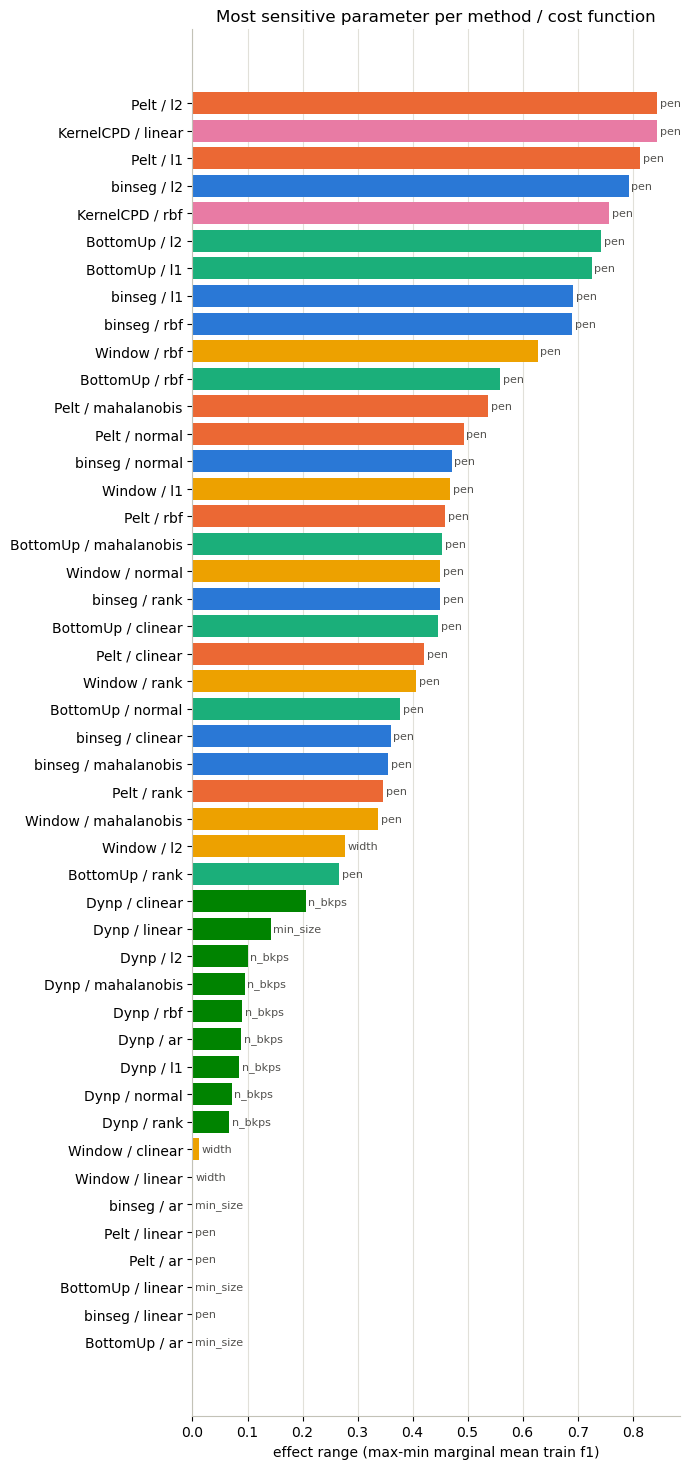

In [11]:
NON_PARAM_COLS = {'cost', 'method', 'mean_precision', 'std_precision', 'mean_recall',
                   'std_recall', 'mean_f1', 'std_f1', 'mean_fp'}

def main_effects_for_group(df, param_cols, metric='mean_f1'):
    """Per-parameter marginal mean of `metric`, averaged over every other parameter
    in this (method, cost) group. Skips any column that wasn't actually varied
    (e.g. a fixed `jump`) -- nothing to measure there."""
    effects = {}
    for p in param_cols:
        if df[p].nunique() <= 1:
            continue
        eff = df.groupby(p)[metric].mean().reset_index().rename(columns={metric: f'mean_{metric}'})
        effects[p] = eff
    return effects

def effect_size_ranking_for_group(effects, metric='mean_f1'):
    col = f'mean_{metric}'
    rows = [dict(param=p, effect_range=eff[col].max() - eff[col].min()) for p, eff in effects.items()]
    return pd.DataFrame(rows).sort_values('effect_range', ascending=False).reset_index(drop=True)

sensitivity_rows = []
for method in METHODS:
    sub = summary_df[summary_df['method'] == method]
    if sub.empty:
        continue
    param_cols = [c for c in sub.columns if c not in NON_PARAM_COLS]
    cost_col = sub['cost'].fillna('n/a') if 'cost' in sub.columns else pd.Series('n/a', index=sub.index)
    for cost, grp in sub.groupby(cost_col):
        ranking = effect_size_ranking_for_group(main_effects_for_group(grp, param_cols))
        for _, row in ranking.iterrows():
            sensitivity_rows.append(dict(method=method, cost=cost,
                                          param=row['param'], effect_range=row['effect_range']))

sensitivity_df = pd.DataFrame(sensitivity_rows).sort_values(
    ['method', 'cost', 'effect_range'], ascending=[True, True, False])
sensitivity_df

 
top_driver = (sensitivity_df.sort_values('effect_range', ascending=False)
              .groupby(['method', 'cost']).first().reset_index()
              .sort_values('effect_range', ascending=False))

fig, ax = plt.subplots(figsize=(7, 0.3 * len(top_driver) + 1))
labels = [f"{m} / {c}" for m, c in zip(top_driver['method'], top_driver['cost'])]
bars = ax.barh(labels, top_driver['effect_range'],
                color=[METHOD_COLORS.get(m, '#898781') for m in top_driver['method']])
for bar, param in zip(bars, top_driver['param']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2, param,
            va='center', fontsize=8, color='#52514e')
ax.invert_yaxis()
ax.set_xlabel('effect range (max-min marginal mean train f1)')
ax.set_title('Most sensitive parameter per method / cost function')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#c3c2b7')
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 49, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-pack

/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 49, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-pack

/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 49, but rank is 0
  warnings.warn('covariance of constraints does not have full '


/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 7, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 5, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/maryamniati/anaconda3/lib/python3.12/site-packa

posx and posy should be finite values


posx and posy should be finite values


... (8 outputs left out)

posx and posy should be finite values


posx and posy should be finite values


posx and posy should be finite values


posx and posy should be finite values


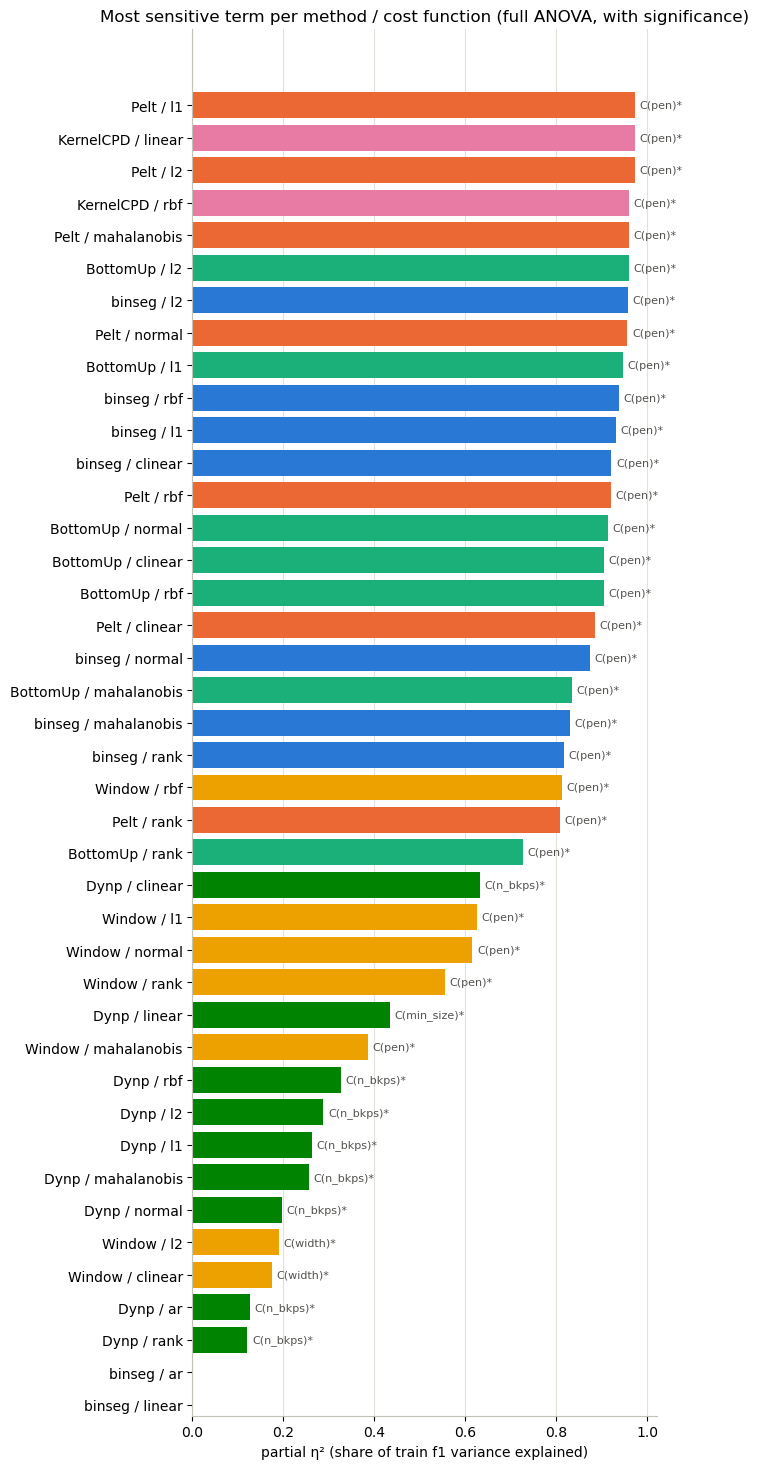

In [12]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

def parameter_sensitivity_anova(df, param_cols, metric="f1", include_interactions=True):
    varied = [p for p in param_cols if df[p].nunique() > 1]
    main_terms = [f"C({p})" for p in varied]
    terms = main_terms.copy()

    if include_interactions:
        terms += [
            f"C({varied[i]}):C({varied[j]})"
            for i in range(len(varied))
            for j in range(i + 1, len(varied))
        ]

    formula = f"{metric} ~ " + " + ".join(terms)
    model = smf.ols(formula, data=df).fit()
    table = sm.stats.anova_lm(model, typ=2)

    residual_ss = table.loc["Residual", "sum_sq"]
    table = table.drop(index="Residual")

    table["partial_eta_squared"] = table["sum_sq"] / (table["sum_sq"] + residual_ss)
    table["percent_explained"] = 100 * table["sum_sq"] / table["sum_sq"].sum()

    return table.sort_values("partial_eta_squared", ascending=False), model


raw_df = load_all("raw")  
RAW_NON_PARAM_COLS = {'cost', 'method', 'pi', 'seed', 'split', 'precision', 'recall', 'f1', 'false_positives'}

param_sensitivity_rows = []
for method in METHODS:
    sub = raw_df[(raw_df['method'] == method) & (raw_df['split'] == 'train')]
    if sub.empty:
        continue
    param_cols = [c for c in sub.columns if c not in RAW_NON_PARAM_COLS]
    cost_col = sub['cost'].fillna('n/a') if 'cost' in sub.columns else pd.Series('n/a', index=sub.index)
    for cost, grp in sub.groupby(cost_col):
        varied = [p for p in param_cols if grp[p].nunique() > 1]
        if len(varied) < 1:
            continue
        table, _ = parameter_sensitivity_anova(grp, varied, metric="f1", include_interactions=True)
        top = table.iloc[0]
        param_sensitivity_rows.append(dict(
            method=method, cost=cost, term=table.index[0],
            partial_eta_squared=top["partial_eta_squared"],
            percent_explained=top["percent_explained"],
            p=top["PR(>F)"],
        ))

param_sensitivity_df = pd.DataFrame(param_sensitivity_rows).sort_values(
    "partial_eta_squared", ascending=False)

fig, ax = plt.subplots(figsize=(7, 0.3 * len(param_sensitivity_df) + 1))
labels = [f"{m} / {c}" for m, c in zip(param_sensitivity_df['method'], param_sensitivity_df['cost'])]
bars = ax.barh(labels, param_sensitivity_df['partial_eta_squared'],
                color=[METHOD_COLORS.get(m, '#898781') for m in param_sensitivity_df['method']])
for bar, term, p in zip(bars, param_sensitivity_df['term'], param_sensitivity_df['p']):
    star = '*' if p < 0.05 else ''
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{term}{star}", va='center', fontsize=8, color='#52514e')
ax.invert_yaxis()
ax.set_xlabel('partial η² (share of train f1 variance explained)')
ax.set_title('Most sensitive term per method / cost function (full ANOVA, with significance)')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#c3c2b7')
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [13]:
raw_df.columns

Index(['cost', 'pen', 'min_size', 'pi', 'seed', 'split', 'precision', 'recall', 'f1', 'false_positives', 'method',
       'jump', 'width', 'n_bkps'],
      dtype='object')

In [14]:
# which parameter is more sensitive, per (method, cost) -- same question as top_driver,
# but from seed-level ANOVA (eta2 = effect size, p = is it real or noise)
sens_rows = []
for _, r in interaction_df.iterrows():
    if r['eta2_a'] >= r['eta2_b']:
        sens_rows.append(dict(method=r['method'], cost=r['cost'],
                               param=r['factor_a'], eta2=r['eta2_a'], p=r['p_a']))
    else:
        sens_rows.append(dict(method=r['method'], cost=r['cost'],
                               param=r['factor_b'], eta2=r['eta2_b'], p=r['p_b']))

top_sensitive = (pd.DataFrame(sens_rows).sort_values('eta2', ascending=False)
                  .groupby(['method', 'cost']).first().reset_index()
                  .sort_values('eta2', ascending=False))

fig, ax = plt.subplots(figsize=(7, 0.3 * len(top_sensitive) + 1))
labels = [f"{m} / {c}" for m, c in zip(top_sensitive['method'], top_sensitive['cost'])]
bars = ax.barh(labels, top_sensitive['eta2'],
                color=[METHOD_COLORS.get(m, '#898781') for m in top_sensitive['method']])
for bar, param, p in zip(bars, top_sensitive['param'], top_sensitive['p']):
    star = '*' if p < 0.05 else ''
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{param}{star}", va='center', fontsize=8, color='#52514e')
ax.invert_yaxis()
ax.set_xlabel('effect size (η², share of F1 variance explained)')
ax.set_title('Most sensitive parameter per method / cost function (seed-level, with significance)')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#c3c2b7')
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

NameError: name 'interaction_df' is not defined

### Pen / min-size grid landscape (train set)

One heatmap per cost function, from `summary.csv` (mean train f1 at every searched `(pen, min_size)` point, not just the winner). The red-outlined cell is the grid-search optimum from `conclusion.csv` -- if it sits on the border of a heatmap, that's the same edge-of-grid issue flagged above, made visible.

Methods with an extra swept parameter (e.g. Window's `width`) are sliced at each cost function's winning value of that parameter, so the heatmap shows the pen x min_size landscape at the setting that was actually chosen -- not an average over all of them.

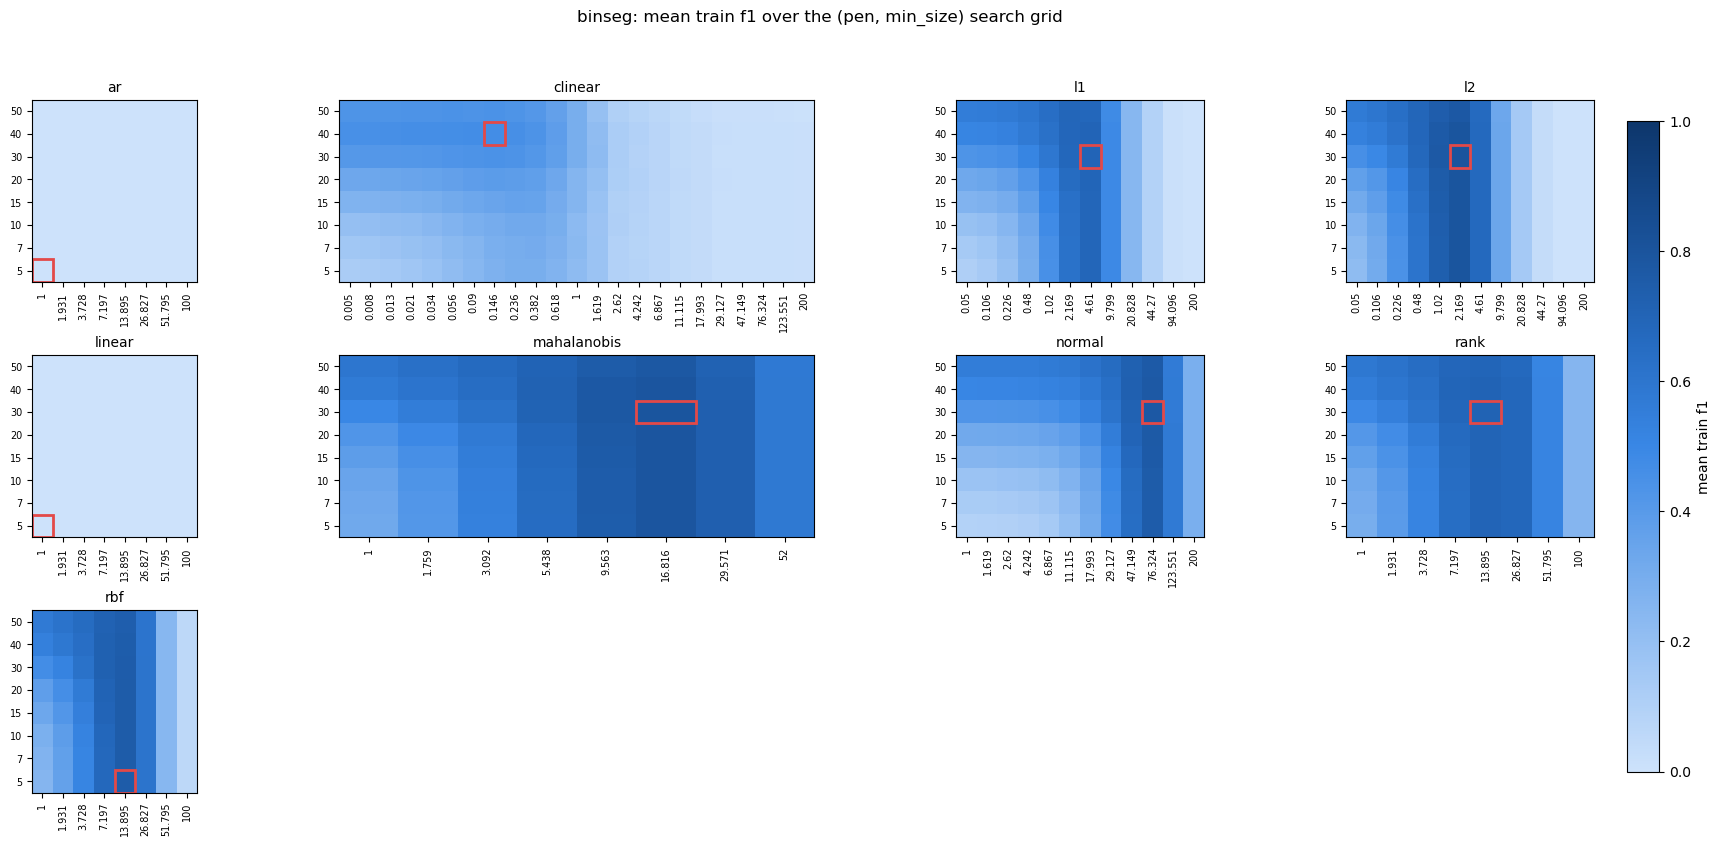

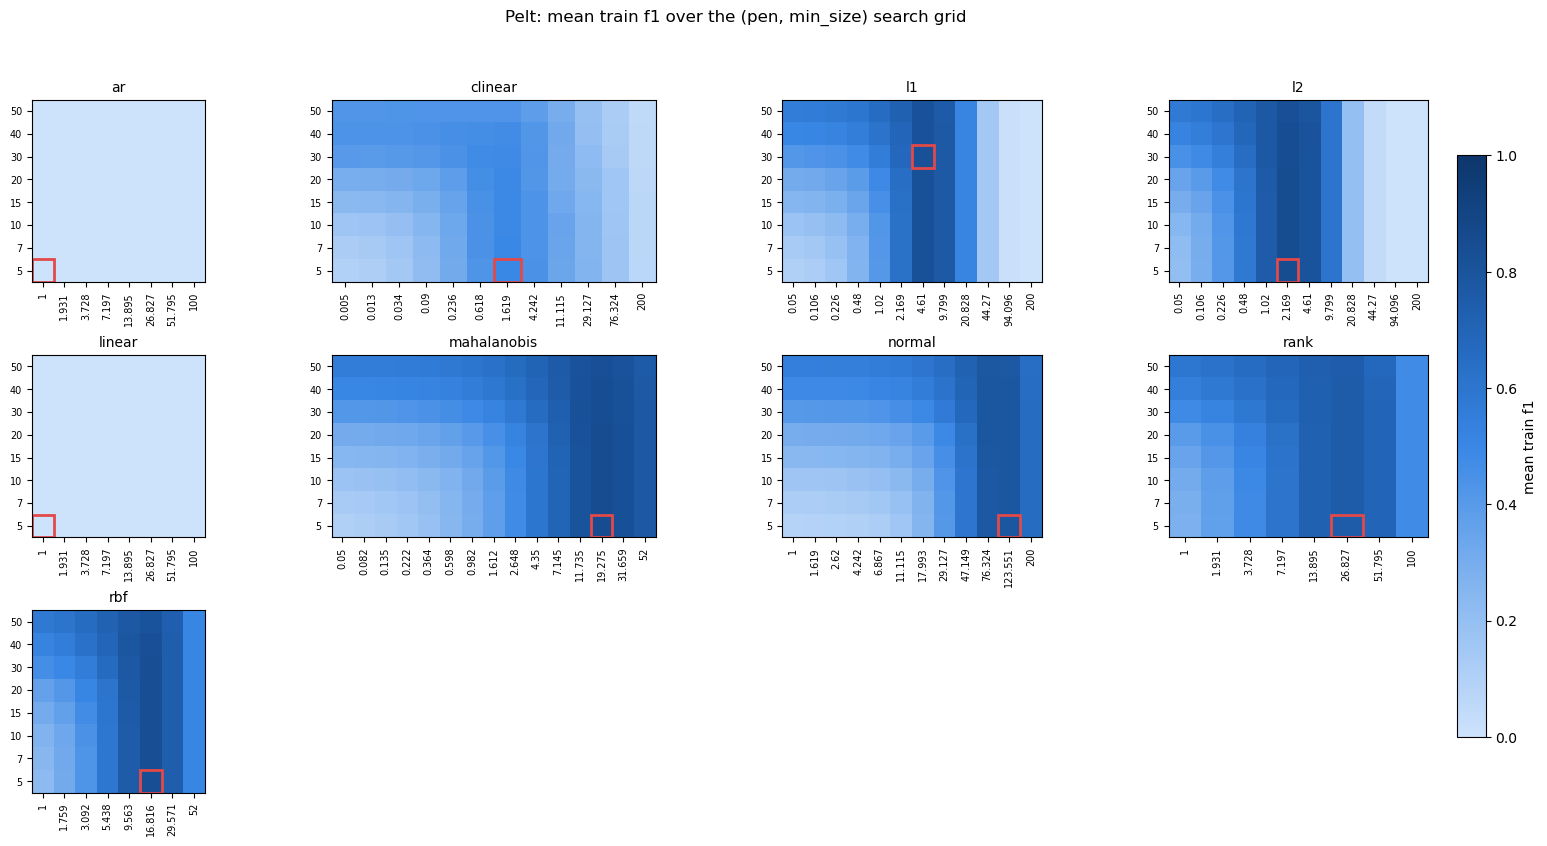

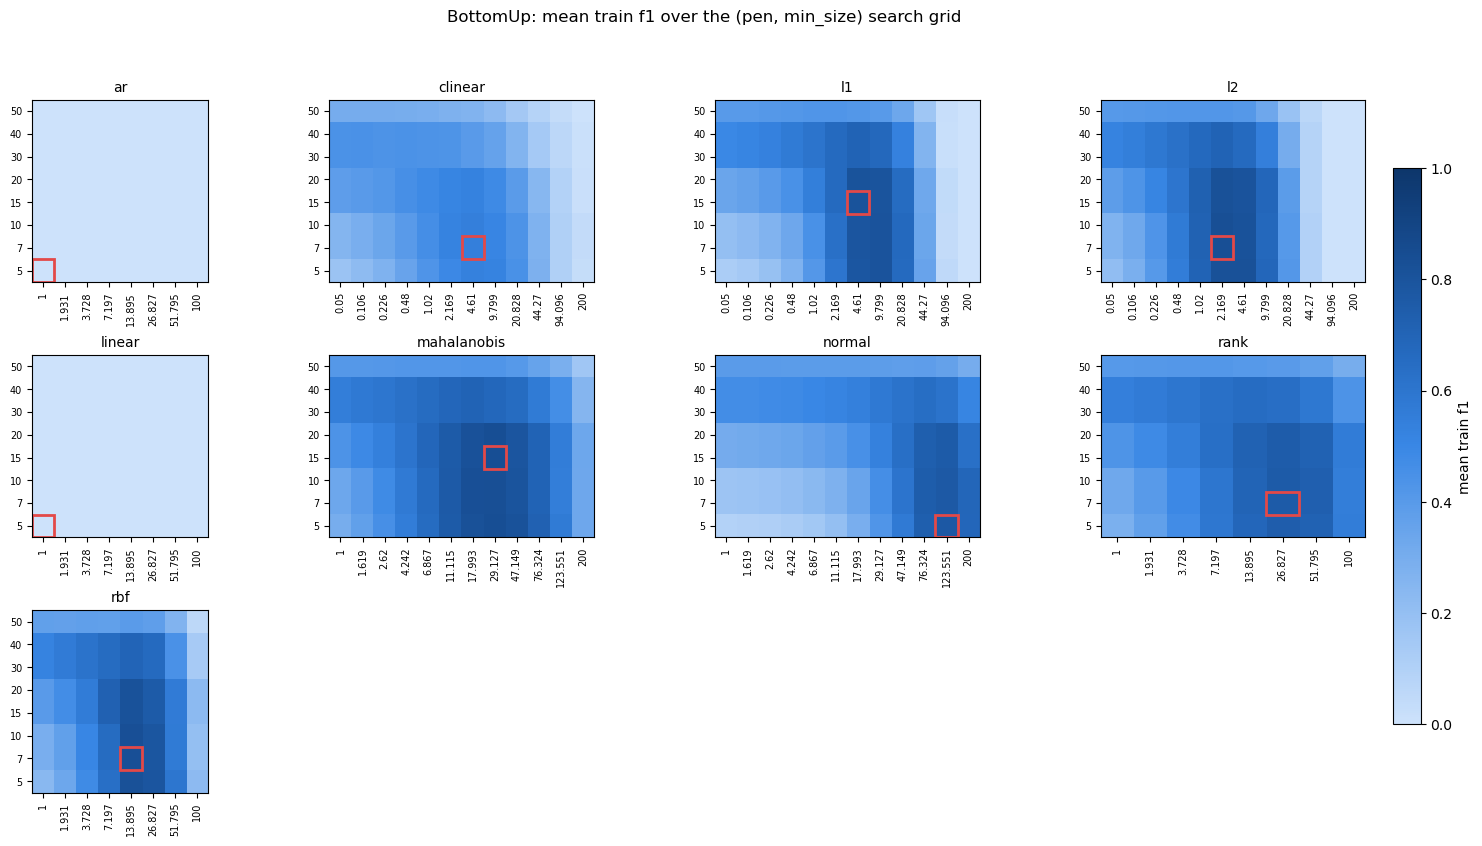

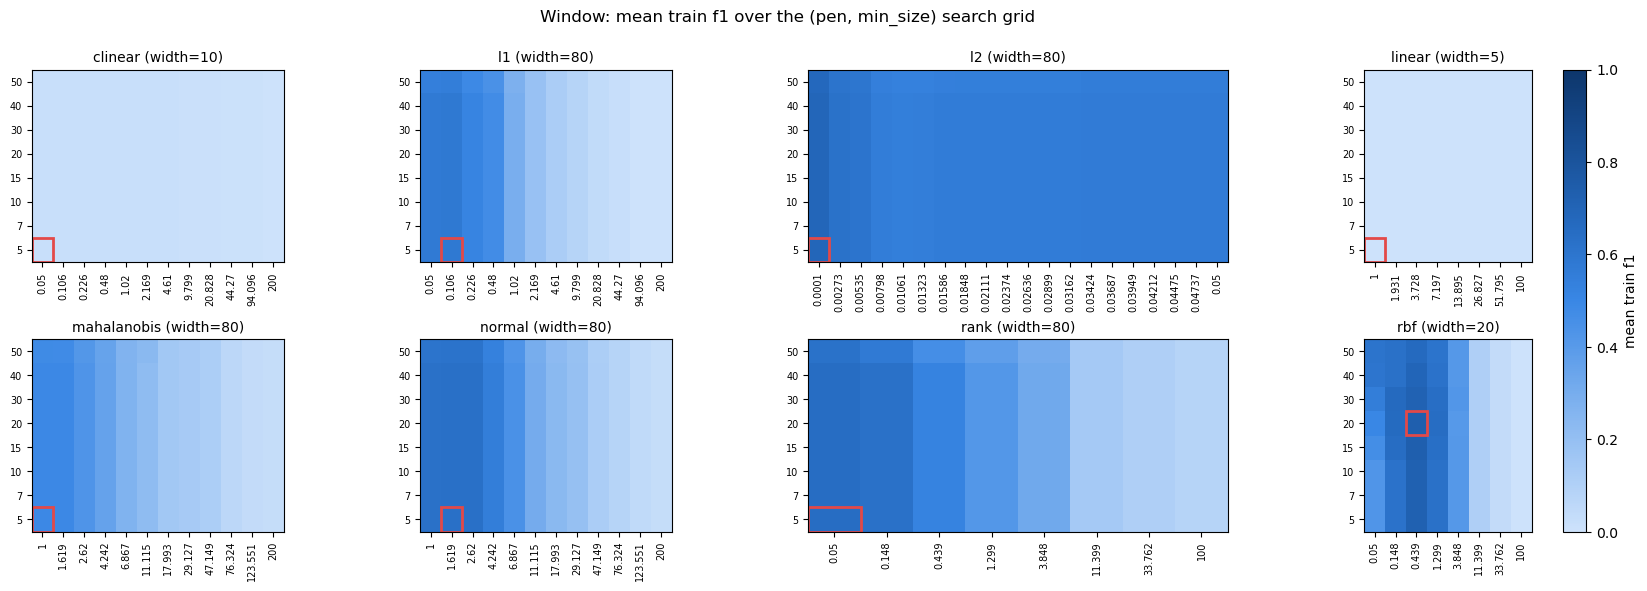

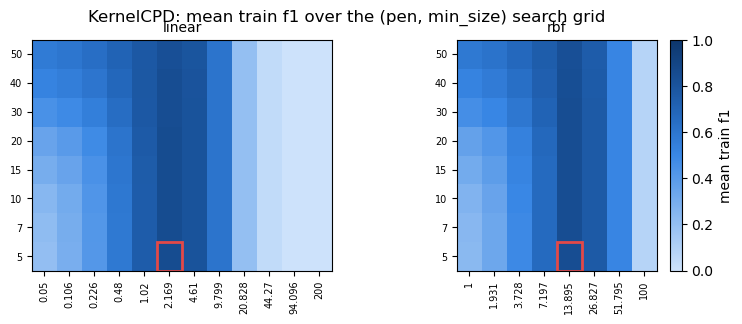

ZeroDivisionError: float division by zero

<Figure size 560x900 with 0 Axes>

In [15]:
from matplotlib.gridspec import GridSpec

# extra swept params beyond pen/min_size that some methods have (name -> conclusion.csv's "best_" column)
EXTRA_GRID_PARAMS = {"width": "best_width", "jump": "best_jump"}

def plot_pen_heatmaps(summary_df, conclusion_df, method, ncols=4):
    sub = summary_df[summary_df["method"] == method]
    costs = sorted(sub["cost"].unique())
    ncols = min(ncols, len(costs))  # avoid empty grid columns when a method has few cost functions (e.g. KernelCPD)
    nrows = int(np.ceil(len(costs) / ncols))

    # how many pen values each cost function has -- clinear-type dense grids get more width
    n_pen = {cost: sub[sub["cost"] == cost]["pen"].nunique() for cost in costs}
    col_widths = [
        max(n_pen[costs[r * ncols + c]] for r in range(nrows) if r * ncols + c < len(costs))
        for c in range(ncols)
    ]

    fig = plt.figure(figsize=(sum(w * 0.28 + 1.4 for w in col_widths), 3.0 * nrows))
    gs = GridSpec(nrows, ncols, figure=fig, width_ratios=col_widths, hspace=0.4, wspace=0.5)
    axes = [[fig.add_subplot(gs[r, c]) for c in range(ncols)] for r in range(nrows)]

    im = None
    for idx, cost in enumerate(costs):
        ax = axes[idx // ncols][idx % ncols]
        cost_sub = sub[sub["cost"] == cost]
        best_rows = conclusion_df[(conclusion_df["method"] == method) & (conclusion_df["cost"] == cost)]
        best = best_rows.iloc[0] if not best_rows.empty else None

        # slice at the winning value of any extra swept param (e.g. Window's width) so the
        # pen x min_size heatmap reflects the setting that was actually chosen, not an average
        title_suffix = ""
        for param, best_col in EXTRA_GRID_PARAMS.items():
            if param in cost_sub.columns and cost_sub[param].nunique() > 1 and best is not None and best_col in best.index:
                cost_sub = cost_sub[cost_sub[param] == best[best_col]]
                title_suffix = f" ({param}={best[best_col]:g})"

        grid = cost_sub.pivot_table(index="min_size", columns="pen", values="mean_f1")
        grid = grid.sort_index().sort_index(axis=1)
        im = ax.imshow(grid.values, cmap=SEQUENTIAL_BLUE, vmin=0, vmax=1, aspect="auto", origin="lower")

        ax.set_xticks(range(len(grid.columns)))
        ax.set_xticklabels([f"{p:g}" for p in grid.columns], rotation=90, fontsize=7)
        ax.set_yticks(range(len(grid.index)))
        ax.set_yticklabels([f"{m:g}" for m in grid.index], fontsize=7)
        ax.set_title(f"{cost}{title_suffix}", fontsize=10)

        if best is not None and best["best_pen"] in grid.columns and best["best_min_size"] in grid.index:
            xi = list(grid.columns).index(best["best_pen"])
            yi = list(grid.index).index(best["best_min_size"])
            ax.add_patch(plt.Rectangle((xi - 0.5, yi - 0.5), 1, 1, fill=False,
                                        edgecolor="#e34948", linewidth=2))

    for j in range(len(costs), nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")

    fig.suptitle(f"{method}: mean train f1 over the (pen, min_size) search grid", y=0.98)
    if im is not None:
        fig.colorbar(im, ax=fig.get_axes(), label="mean train f1", fraction=0.02, pad=0.02)
    return fig

for method in METHODS:
    fig = plot_pen_heatmaps(summary_df, all_df, method)
    plt.show()